In [1]:
using TensorsLite # para usar o 𝐢 e 𝐣 abaixo
using VoronoiMeshes
using NCDatasets # para ler malhas de um arquivo .nc
using DelaunayTriangulation # para fazer triangulação de Voronoi para gerar novas malhas
using GLMakie
using JLD2
include("juliaDEC.jl")
@load "lsq_matrices.jld2" matrices_regular matrices_irregular

2-element Vector{Symbol}:
 :matrices_regular
 :matrices_irregular

In [2]:
function deform_points!(points, base_displacement)
    for i in eachindex(points)
#       esta parte gera um número entre -1 e 1
#             |------------|
        dp = ((2*rand() - 1)*base_displacement)*𝐢 + ((2*rand() - 1)*base_displacement)*𝐣
        points[i] = points[i] + dp
    end
    return points
end

function deform_only_one_point!(points, base_displacement, point_index)
    points[point_index] = points[point_index] + base_displacement*𝐢 + base_displacement*𝐣
    return points
end


deform_only_one_point! (generic function with 1 method)

Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes


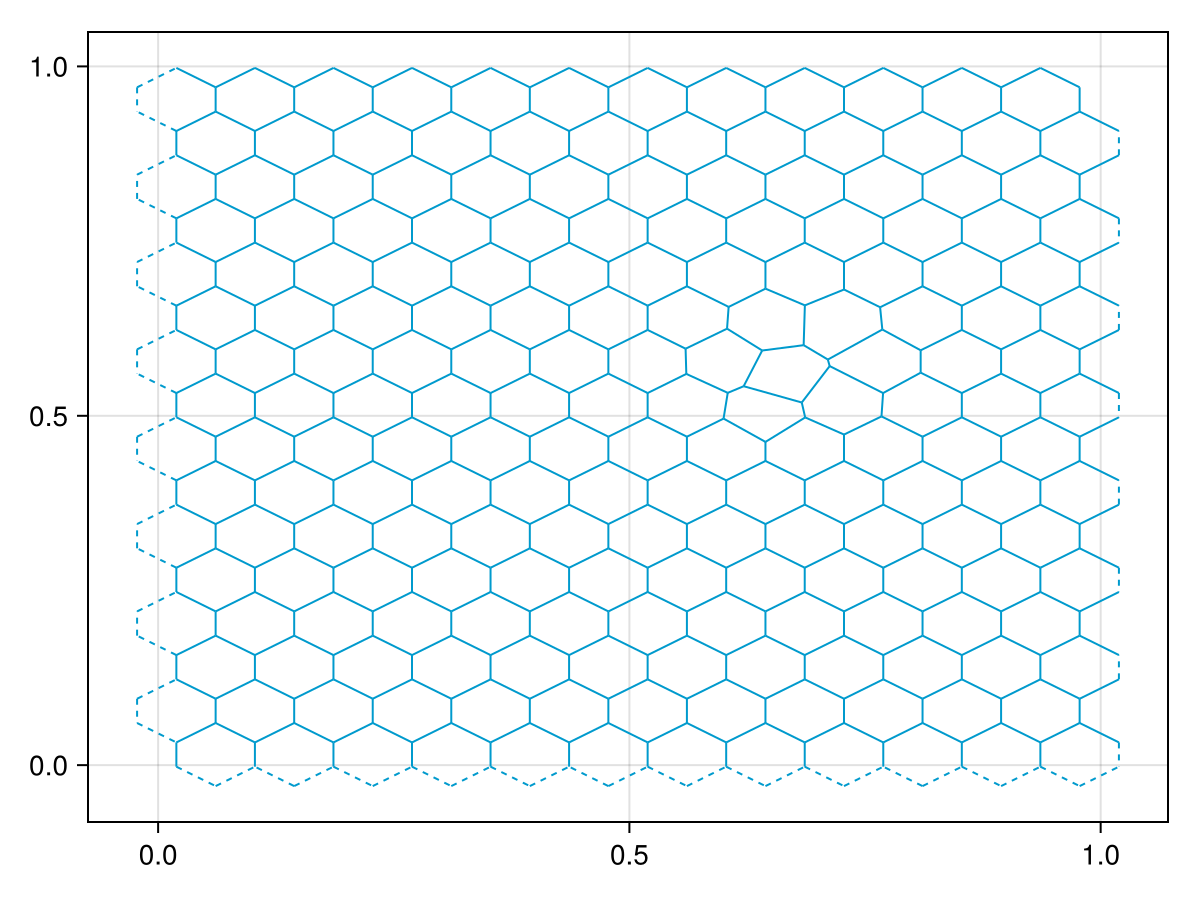

In [3]:
i = 3
alpha = -0.5
mesh = VoronoiMesh("meshes/mesh$(i)_regular.nc")
fig = Figure(size = (800, 600))
ax = Axis(fig[1, 1])
new_voronoi_generators = copy(mesh.cells.position)
deform_only_one_point!(new_voronoi_generators, alpha*minimum(mesh.edges.lengthDual), 100)
new_mesh = VoronoiMesh(new_voronoi_generators, mesh.x_period, mesh.y_period; max_iter = 0)
plotmesh(new_mesh)

In [34]:
new_mesh.cells.position[1]

3-element Vec2Dxy{Float64}:
 0.22774652760672343
 0.2652264455006792
 𝟎

In [4]:
alpha = [0.02, 0.04, 0.08, 0.16, 0.32]

# Initialize data storage
results = []

i = 3
mesh = VoronoiMesh("meshes/mesh$(i)_regular.nc")
new_voronoi_generators = copy(mesh.cells.position)

for a in alpha
    deform_only_one_point!(new_voronoi_generators, a*minimum(mesh.edges.lengthDual), 100)
    new_mesh = VoronoiMesh(new_voronoi_generators, mesh.x_period, mesh.y_period; max_iter = 0);
    d0 = d0_matrix_primal(new_mesh)
    d1 = d1_matrix_dual(new_mesh)

    star1_lsq = hodge_star_lsq_matrix(new_mesh, true, false)
    G3_lsq = d1 * star1_lsq  * d0
    eig3_lsq = eigvals(Matrix(G3_lsq))
    
    # Get the eigenvalue with maximum absolute value (not just complex part)
    max_eig_lsq = eig3_lsq[argmax(abs.(eig3_lsq))]
    
    # Store results
    push!(results, (
        mesh_id = i,
        alpha = a,
        max_eig_lsq = max_eig_lsq,
        eigenvalue_highest_complex_part = eig3_lsq[argmax(abs.(imag(eig3_lsq)))]
    ))
end

print(results)

Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Any[(mesh_id = 3, alpha = 0.02, max_eig_lsq = -6.046622039600218 + 0.0im, e

In [5]:
results

5-element Vector{Any}:
 (mesh_id = 3, alpha = 0.02, max_eig_lsq = -6.046622039600218 + 0.0im, eigenvalue_highest_complex_part = -3.471076801948623 - 0.0006061948784369988im)
 (mesh_id = 3, alpha = 0.04, max_eig_lsq = -6.046484015783034 + 0.0im, eigenvalue_highest_complex_part = -3.937496698215659 - 0.00196601061023547im)
 (mesh_id = 3, alpha = 0.08, max_eig_lsq = -6.045781686274901 + 0.0im, eigenvalue_highest_complex_part = -3.0312908863765258 - 0.0077653237871978436im)
 (mesh_id = 3, alpha = 0.16, max_eig_lsq = -6.0425185925105245 + 0.0im, eigenvalue_highest_complex_part = -3.0456301549847637 - 0.027451486644886676im)
 (mesh_id = 3, alpha = 0.32, max_eig_lsq = -6.009189836099582 + 0.0im, eigenvalue_highest_complex_part = -1.57107420919912 - 0.0612076617806209im)

In [6]:
alpha = [0.0005, 0.001, 0.002, 0.004, 0.008, 0.016]

# Initialize data storage
results = []
all_eigenvalues = Dict()  # Store all eigenvalues for each alpha

i = 3
mesh = VoronoiMesh("meshes/mesh$(i)_regular.nc")
new_voronoi_generators = copy(mesh.cells.position)

for a in alpha
    deform_only_one_point!(new_voronoi_generators, a*minimum(mesh.edges.lengthDual), 100)
    new_mesh = VoronoiMesh(new_voronoi_generators, mesh.x_period, mesh.y_period; max_iter = 0);
    d0 = d0_matrix_primal(new_mesh)
    d1 = d1_matrix_dual(new_mesh)

    star1_lsq = hodge_star_lsq_matrix(new_mesh, true, false)
    G3_lsq = d1 * star1_lsq  * d0
    eig3_lsq = eigvals(Matrix(G3_lsq))
    
    # Store all eigenvalues for this alpha
    all_eigenvalues[a] = eig3_lsq
    
    # Get the eigenvalue with maximum absolute value (not just complex part)
    max_eig_lsq = eig3_lsq[argmax(abs.(eig3_lsq))]
    
    # Store results
    push!(results, (
        mesh_id = i,
        alpha = a,
        max_eig_lsq = max_eig_lsq,
        eigenvalue_highest_complex_part = eig3_lsq[argmax(abs.(imag(eig3_lsq)))]
    ))
end

results


Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum num

6-element Vector{Any}:
 (mesh_id = 3, alpha = 0.0005, max_eig_lsq = -6.046639221083315 + 0.0im, eigenvalue_highest_complex_part = -3.4710049049185985 - 1.5228369160054468e-5im)
 (mesh_id = 3, alpha = 0.001, max_eig_lsq = -6.046639135156079 + 0.0im, eigenvalue_highest_complex_part = -3.4710052683443826 - 4.568402907309701e-5im)
 (mesh_id = 3, alpha = 0.002, max_eig_lsq = -6.046638705514785 + 0.0im, eigenvalue_highest_complex_part = -3.471007084951571 - 0.00010658347881050733im)
 (mesh_id = 3, alpha = 0.004, max_eig_lsq = -6.046636814991863 + 0.0im, eigenvalue_highest_complex_part = -3.471015066724285 - 0.00022827408273353112im)
 (mesh_id = 3, alpha = 0.008, max_eig_lsq = -6.046628907379775 + 0.0im, eigenvalue_highest_complex_part = -3.471048247248456 - 0.000470723460528042im)
 (mesh_id = 3, alpha = 0.016, max_eig_lsq = -6.046596559381629 + 0.0im, eigenvalue_highest_complex_part = -3.4711807189191903 - 0.0009475669168395145im)

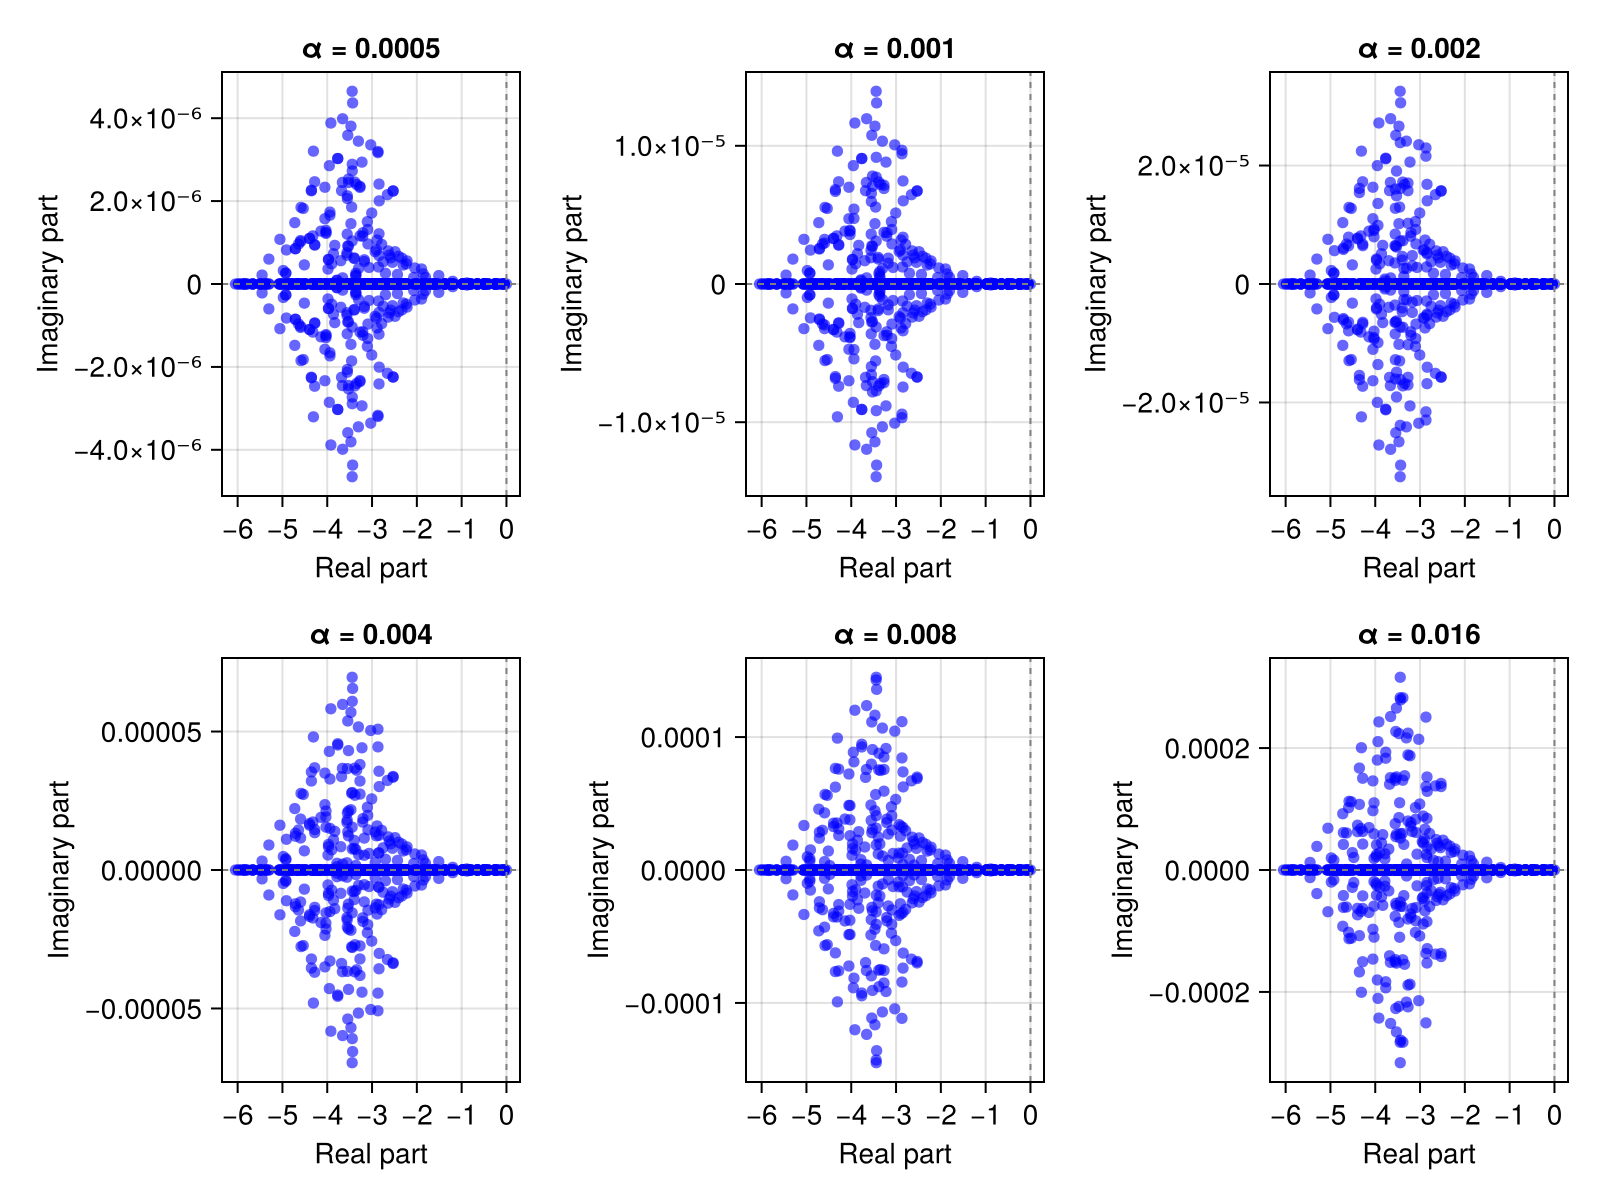

In [71]:
# Plot eigenvalues in the complex plane for each alpha
fig = Figure(size = (800, 600))

# Create subplots for each alpha
for (idx, a) in enumerate(alpha)
    col = idx
    row = 1
    if col > 3
        row = 2
        col = col - 3
    end
    ax = Axis(fig[row, col], 
        xlabel = "Real part",
        ylabel = "Imaginary part",
        title = "α = $a"
    )
    
    eigs = all_eigenvalues[a]
    scatter!(ax, real(eigs), imag(eigs), markersize = 8, color = :blue, alpha = 0.6)
    
    # Add zero lines for reference
    hlines!(ax, [0], color = :gray, linestyle = :dash, linewidth = 1)
    vlines!(ax, [0], color = :gray, linestyle = :dash, linewidth = 1)
end
fig


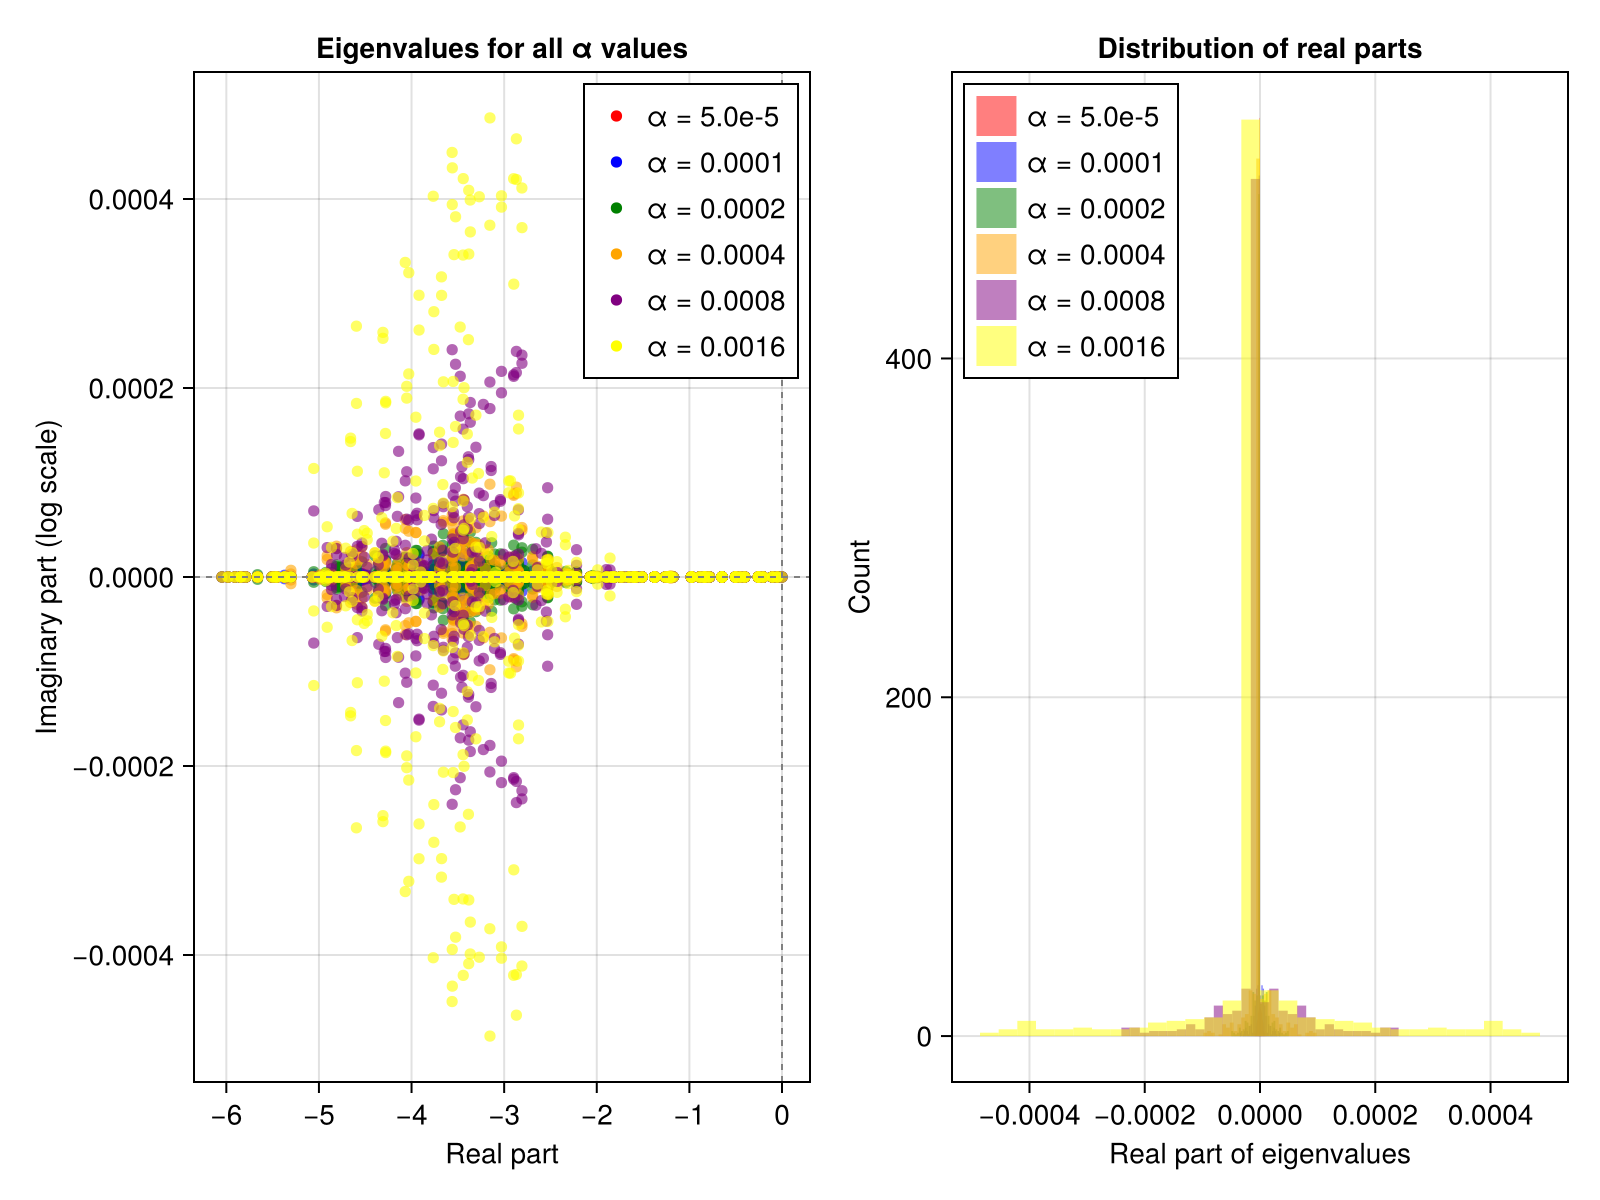

In [26]:
# Additional visualization: overlay all eigenvalues on a single plot
fig2 = Figure(size = (800, 600))

# Complex plane plot with all alphas overlaid
ax1 = Axis(fig2[1, 1], 
    xlabel = "Real part",
    ylabel = "Imaginary part (log scale)",
    title = "Eigenvalues for all α values",
)

colors = [:red, :blue, :green, :orange, :purple, :yellow]
for (idx, a) in enumerate(alpha)
    eigs = all_eigenvalues[a]
    scatter!(ax1, real(eigs), imag(eigs), 
        markersize = 8, 
        color = colors[idx], 
        alpha = 0.6,
        label = "α = $a")
end

hlines!(ax1, [0], color = :gray, linestyle = :dash, linewidth = 1)
vlines!(ax1, [0], color = :gray, linestyle = :dash, linewidth = 1)
axislegend(ax1, position = :rt)

# Real part histogram
ax2 = Axis(fig2[1, 2], 
    xlabel = "Real part of eigenvalues",
    ylabel = "Count",
    title = "Distribution of real parts"
)

for (idx, a) in enumerate(alpha)
    eigs = all_eigenvalues[a]
    hist!(ax2, imag(eigs), bins = 30, color = (colors[idx], 0.5), 
        label = "α = $a")
end

axislegend(ax2, position = :lt)

fig2


In [ ]:
# Plot how eigenvalue statistics change with alpha
fig3 = Figure(size = (1200, 400))

# Maximum absolute eigenvalue vs alpha
ax1 = Axis(fig3[1, 1], 
    xlabel = "α",
    ylabel = "Maximum |eigenvalue|",
    title = "Maximum absolute eigenvalue"
)

max_abs_eigs = [maximum(abs.(all_eigenvalues[a])) for a in alpha]
lines!(ax1, alpha, max_abs_eigs, color = :blue, linewidth = 2)
scatter!(ax1, alpha, max_abs_eigs, color = :blue, markersize = 12)

# Maximum imaginary part vs alpha
ax2 = Axis(fig3[1, 2], 
    xlabel = "α",
    ylabel = "Maximum |Im(eigenvalue)|",
    title = "Maximum imaginary part"
)

max_imag_eigs = [maximum(abs.(imag(all_eigenvalues[a]))) for a in alpha]
lines!(ax2, alpha, max_imag_eigs, color = :red, linewidth = 2)
scatter!(ax2, alpha, max_imag_eigs, color = :red, markersize = 12)

# Mean real part vs alpha
ax3 = Axis(fig3[1, 3], 
    xlabel = "α",
    ylabel = "Mean real part",
    title = "Mean real part of eigenvalues"
)

mean_real_eigs = [mean(real(all_eigenvalues[a])) for a in alpha]
lines!(ax3, alpha, mean_real_eigs, color = :green, linewidth = 2)
scatter!(ax3, alpha, mean_real_eigs, color = :green, markersize = 12)

fig3
